In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import os

# Set the style parameters
mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
# plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
# plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.serif"] = ["Computer Modern Roman"]
fontsize= 27
colors = ["tab:red", "tab:blue"]

In [2]:
# Read results
datasets = ["reference", "plant", "marine"]
dataset_ids = [5, 6]
seed_values = ["1", "2", "3", "4", "5"]
dim_values = [4, 16, 64, 128, 256, 512]
dataset_name2label = {
    "reference": r"\textsl{Reference}", "plant": r"\textsl{Plant}", "marine": r"\textsl{Marine}"
}

# Read the files
results = dict()
for dataset in datasets:
    results[dataset] = dict()

    for dataset_id in [5, 6]:
        results[dataset][dataset_id] = dict()

        for dim in dim_values:
            results[dataset][dataset_id][dim] = dict()

            for seed in seed_values:
                results[dataset][dataset_id][dim][seed] = dict()
                results[dataset][dataset_id][dim][seed][5] = dict()
                results[dataset][dataset_id][dim][seed][6] = dict()

                # Define the file name
                if dim == 256:

                    filename = f"k=4_d={dim}_negperpos=200_maxseq=100000_epoch=25_lr=0.001_batch=100000_loss=mahalanobis"
                    filename += f"_strategy=var_only_seed={seed}_factortest.modelsonolsun_metric-mahalanobis"
                    result_path = os.path.join(os.getcwd(), "results", dataset, filename + ".results")
                else:
                    filename = f"k=4_d={dim}_negperpos=200_maxseq=100000_epoch=25_lr=0.001_batch=100000_loss=mahalanobis"
                    filename += f"_strategy=var_only_seed={seed}.model_metric-mahalanobis"
                    result_path = os.path.join(os.getcwd(), "results", "ablation", "dim", dataset, filename + ".results")

                with open(result_path, "r") as f:
                    for line_num, line in enumerate(f.readlines()):

                        if line_num == 2:
                            values = list(map(int, line.strip()[17:-1].split(', ')))
                            results[dataset][dataset_id][dim][seed][5]['recall'] = values
                        if line_num == 3:
                            values = list(map(int, line.strip()[20:-1].split(', ')))
                            results[dataset][dataset_id][dim][seed][5]['precision'] = values
                        if line_num == 4:
                            values = list(map(int, line.strip()[13:-1].split(', ')))
                            results[dataset][dataset_id][dim][seed][5]['f1'] = values

                        if line_num == 9:
                            values = list(map(int, line.strip()[17:-1].split(', ')))
                            results[dataset][dataset_id][dim][seed][6]['recall'] = values
                        if line_num == 10:
                            values = list(map(int, line.strip()[20:-1].split(', ')))
                            results[dataset][dataset_id][dim][seed][6]['precision'] = values
                        if line_num == 11:
                            values = list(map(int, line.strip()[13:-1].split(', ')))
                            results[dataset][dataset_id][dim][seed][6]['f1'] = values

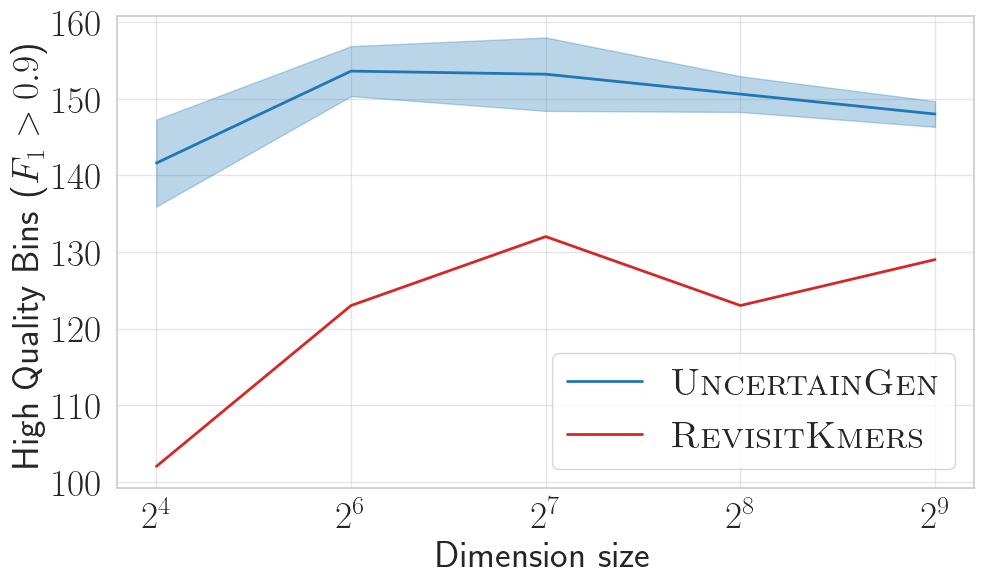

In [5]:
dataset = "reference"
dataset_id = 5

chosen_dim_indices = np.asarray([1, 2, 3, 4, 5])
revisit_kmers = [102, 123, 132, 123, 129]

plt.figure(figsize=(10, 6))
# A tensor of shape (number of seeds, number of dimensions, number of bin thresholds)
values = np.asarray([
    [results[dataset][dataset_id][dim][seed][dataset_id]['f1'] for dim in dim_values] for seed in seed_values
])
values_avg = values.mean(axis=0, keepdims=False)[:, -1] # Get tha last element, i.e. HQ > 0.9
values_std = values.std(axis=0, keepdims=False)[:, -1] # Get tha last element, i.e. HQ > 0.9

plt.plot(
    np.arange(len(dim_values))[chosen_dim_indices], values_avg[chosen_dim_indices], '-', label=r"\textsc{UncertainGen}", color=colors[1], linewidth=2
)
plt.fill_between(
    np.arange(len(dim_values))[chosen_dim_indices], (values_avg - values_std)[chosen_dim_indices], (values_avg + values_std)[chosen_dim_indices], alpha=0.3, color=colors[1]
)
plt.plot(
    np.arange(len(dim_values))[chosen_dim_indices], revisit_kmers, '-', label=r"\textsc{RevisitKmers}", color=colors[0], linewidth=2
)
plt.xlabel(r"Dimension size", fontsize=fontsize)
plt.ylabel(r"High Quality Bins ($F_1 > 0.9$)", fontsize=fontsize)
# plt.xticks(fontsize=fontsize)
plt.xticks(np.arange(len(dim_values))[chosen_dim_indices], [rf"$2^{p}$" for p in [4, 6, 7, 8, 9]], fontsize=fontsize)
#
plt.yticks(fontsize=fontsize)
plt.legend(fontsize=fontsize)
plt.grid(True, alpha=0.5)
plt.tight_layout()
# plt.show()
plt.savefig(
    os.path.join(os.getcwd(), "figures", f"single_dim_impact_{dataset}_{dataset_id}.png"),
    dpi=300, bbox_inches='tight'
)

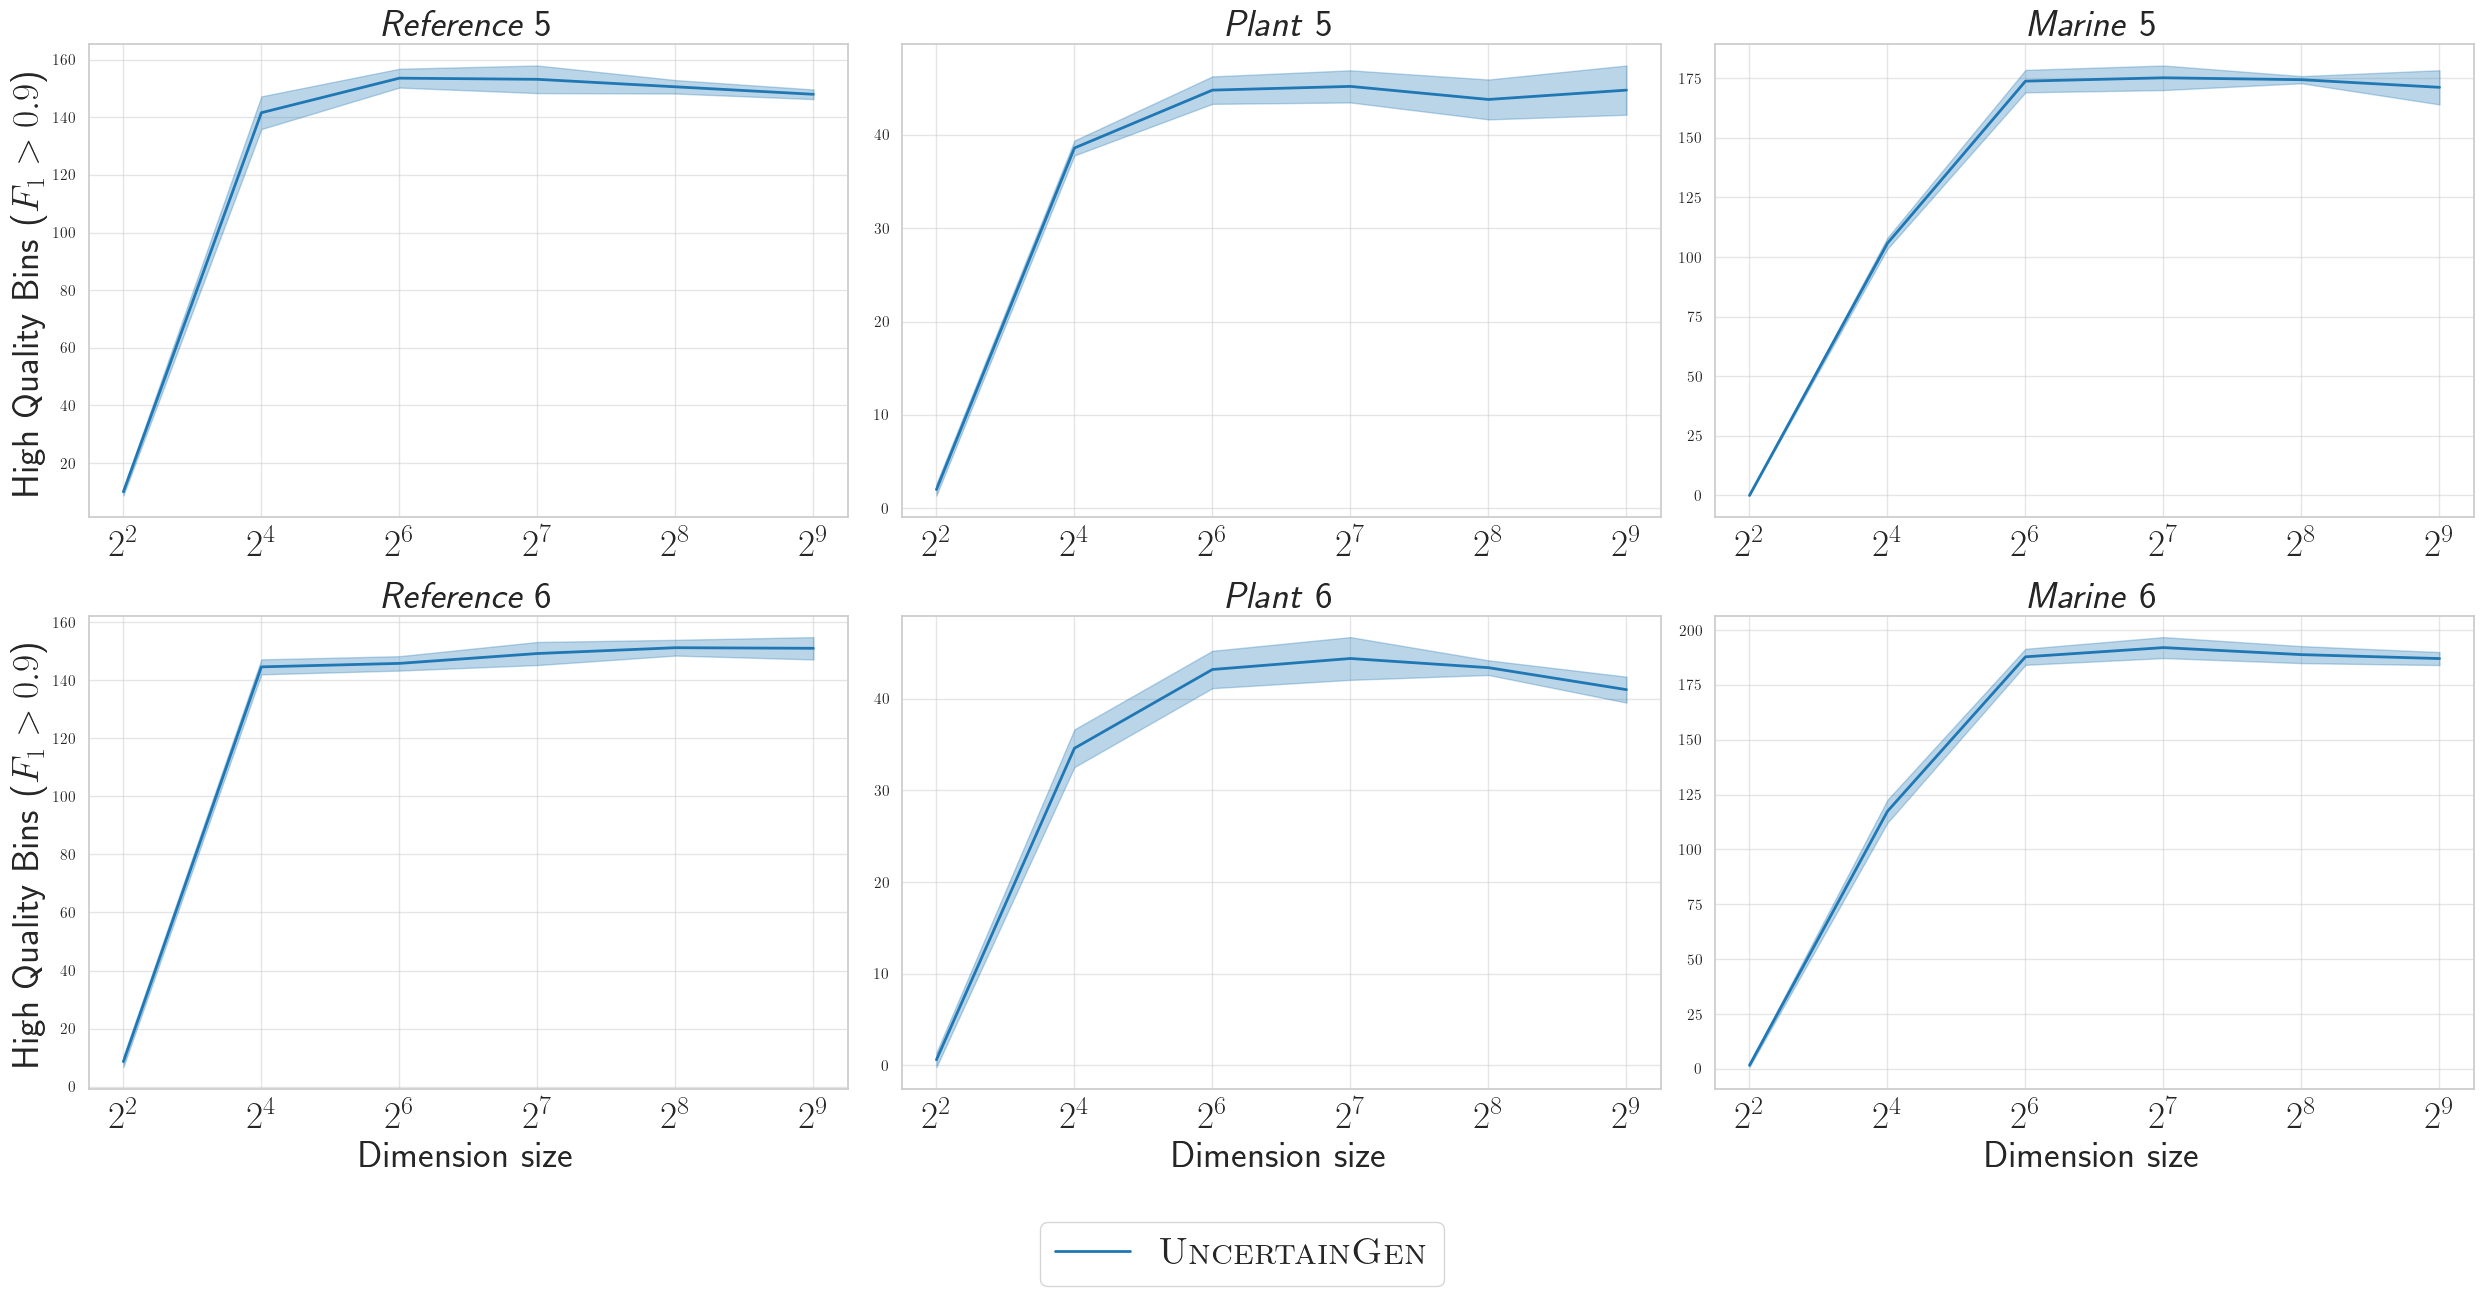

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(25, 12))

for i, dataset in enumerate(datasets):
    for j, dataset_id in enumerate(dataset_ids):

        # A tensor of shape (number of seeds, number of dimensions, number of bin thresholds)
        values = np.asarray([
            [results[dataset][dataset_id][dim][seed][dataset_id]['f1'] for dim in dim_values] for seed in seed_values
        ])
        values_avg = values.mean(axis=0, keepdims=False)[:, -1] # Get tha last element, i.e. HQ > 0.9
        values_std = values.std(axis=0, keepdims=False)[:, -1] # Get tha last element, i.e. HQ > 0.9

        axes[j, i].plot(
            range(len(dim_values)), values_avg, '-', label=r"\textsc{UncertainGen}", color=colors[1], linewidth=2
        )
        axes[j, i].fill_between(
            range(len(dim_values)), values_avg - values_std, values_avg + values_std, alpha=0.3, color=colors[1]
        )
        axes[j, i].set_title(f"{dataset_name2label[dataset]} {dataset_id}", fontsize=fontsize)
        if j == 1:
            axes[j, i].set_xlabel(r"Dimension size", fontsize=fontsize)
        if i == 0:
            axes[j, i].set_ylabel(r"High Quality Bins ($F_1 > 0.9$)", fontsize=fontsize)
        # # plt.xticks(fontsize=fontsize)
        axes[j, i].set_xticks(range(len(dim_values)), [rf"$2^{p}$" for p in [2, 4, 6, 7, 8, 9]], fontsize=fontsize)
        axes[j, i].grid(True, alpha=0.5)
        # #
        # plt.yticks(fontsize=fontsize)
# Add the legend out of the plot and below in one line
legend = fig.legend(
    labels=[r"\textsc{UncertainGen}",], loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=fontsize
)
plt.tight_layout()
# plt.show()
plt.savefig(
    os.path.join(os.getcwd(), "figures", f"all_dim_impact.png"), dpi=300, bbox_inches='tight'
)